# Schritt 4 – Finale Auswertung der Real-World-Graphen

Dieses Notebook liest die auf dem Server erzeugten 1000-Run-CSV-Dateien für ATT-MPLS, Cogentco und Oteglobe.

In [1]:
from pathlib import Path
import sys

repo_root = Path.cwd().resolve()
while repo_root != repo_root.parent and not (repo_root / 'schritt4_algorithmen_vergleich').exists():
    repo_root = repo_root.parent
step_root = repo_root / 'schritt4_algorithmen_vergleich'
sys.path.insert(0, str(step_root / 'src'))
sys.path.insert(0, str(step_root / 'evaluation'))

import routing_algorithms as routing
from result_analysis import (
    aggregate_results, completeness_table, load_result_directories,
    plot_all_comparisons, validate_summary,
)

EXPECTED_RUNS = 1000
DATASETS = {
    'attmpls': step_root / 'output' / 'server' / 'real_attmpls',
    'cogentco': step_root / 'output' / 'server' / 'real_cogentco',
    'oteglobe': step_root / 'output' / 'server' / 'real_oteglobe',
}
DISPLAY_NAMES = {'attmpls': 'ATT-MPLS (n=25)', 'cogentco': 'Cogentco (n=197)', 'oteglobe': 'Oteglobe (n=93)'}
OUTPUT_DIR = step_root / 'evaluation' / 'output' / 'real_world_graphs_runs1000'

## Pilotlauf

Die folgenden Zellen erzeugen bzw. prüfen kleine Pilotdaten und dienen als technische Kontrolle vor der finalen 1000-Run-Auswertung.


In [2]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

repo_root = Path.cwd().resolve()
while repo_root != repo_root.parent and not (repo_root / 'schritt4_algorithmen_vergleich').exists():
    repo_root = repo_root.parent

step_root = repo_root / 'schritt4_algorithmen_vergleich'
src_root = step_root / 'src'
sys.path.insert(0, str(src_root))

import experiment
import routing_algorithms as routing

topology_root = repo_root / 'schritt3_knoten_disjunkte_pfade' / 'data' / 'topology_zoo'
data_root = step_root / 'output' / 'real_world_graphs_pilot_data'
plot_dir = step_root / 'evaluation' / 'output' / 'real_world_graphs_pilot'
data_root.mkdir(parents=True, exist_ok=True)
plot_dir.mkdir(parents=True, exist_ok=True)

TOPOLOGIES = {
    'attmpls': topology_root / 'AttMpls.graphml',
    'cogentco': topology_root / 'Cogentco.graphml',
    'oteglobe': topology_root / 'Oteglobe.graphml',
}
DISPLAY_NAMES = {'attmpls': 'ATT-MPLS (n=25)', 'cogentco': 'Cogentco (n=197)', 'oteglobe': 'Oteglobe (n=93)'}
RUNS = 5
FAIL_FACTORS = [1.0, 2.0, 3.0]
FAILURE_STARTS = [0.3, 0.6, 0.9]
FAILURE_DROP = 0.3
SEED = 123

assert all(path.exists() for path in TOPOLOGIES.values())
print('Topologien:', ', '.join(DISPLAY_NAMES.values()))
print('Pilotdaten:', data_root)
print('Plots:', plot_dir)

Topologien: ATT-MPLS (n=25), Cogentco (n=197), Oteglobe (n=93)
Pilotdaten: C:\Users\test\ba-gamous-disjoint\schritt4_algorithmen_vergleich\output\real_world_graphs_pilot_data
Plots: C:\Users\test\ba-gamous-disjoint\schritt4_algorithmen_vergleich\evaluation\output\real_world_graphs_pilot


## Pilotdaten erzeugen

Pro Topologie entstehen zwölf CSV-Dateien: drei Parameterwerte für jede der vier Failure-Kombinationen. Jede Datei enthält `5 Runs × 6 Algorithmen = 30` Zeilen. Vollständige vorhandene Pilotdaten werden wiederverwendet.

In [3]:
expected_files_per_topology = 2 * len(FAIL_FACTORS) + 2 * len(FAILURE_STARTS)
expected_rows_per_file = RUNS * len(routing.ALGORITHMS)
csv_paths = []

for graph_name, graphml_path in TOPOLOGIES.items():
    topology_output = data_root / graph_name
    existing = sorted(topology_output.glob('algorithms_*.csv'))
    complete = (
        len(existing) == expected_files_per_topology
        and all(len(pd.read_csv(path)) == expected_rows_per_file for path in existing)
    )
    if complete:
        generated = [str(path) for path in existing]
        print(f'{DISPLAY_NAMES[graph_name]}: vollständige Pilotdaten wiederverwendet')
    else:
        print(f'{DISPLAY_NAMES[graph_name]}: Pilotdaten werden erzeugt ...')
        generated = experiment.run_experiment_series(
            runs=RUNS,
            failure_types=['link', 'node'],
            failure_models=['random', 'clustered'],
            algorithms=routing.ALGORITHMS,
            graphml_path=graphml_path,
            graph_name=graph_name,
            fail_factors=FAIL_FACTORS,
            failure_starts=FAILURE_STARTS,
            failure_drop=FAILURE_DROP,
            output_dir=topology_output,
            seed=SEED,
        )
    csv_paths.extend(generated)

print(f'{len(csv_paths)} CSV-Dateien mit jeweils {expected_rows_per_file} Zeilen')

ATT-MPLS (n=25): vollständige Pilotdaten wiederverwendet
Cogentco (n=197): vollständige Pilotdaten wiederverwendet
Oteglobe (n=93): vollständige Pilotdaten wiederverwendet
36 CSV-Dateien mit jeweils 30 Zeilen


## Rohdaten aggregieren

Die X-Achse wird in den Plots paper-nah als **Failure Rate** bezeichnet. Technisch entspricht `failureParameter` bei Random Failures dem `failFactor` und bei Clustered Failures dem `failureStart`. Resilience ist die Erfolgsquote. Durchschnittliche Hops und Stretch werden ausschließlich für erfolgreiche Routings berechnet.

In [4]:
raw = pd.concat([pd.read_csv(path) for path in sorted(map(Path, csv_paths))], ignore_index=True)
for column in ['success', 'hops', 'stretch', 'failFactor', 'failureStart']:
    raw[column] = pd.to_numeric(raw[column], errors='coerce')
raw['hopsSuccessful'] = raw['hops'].where(raw['success'] == 1)
raw['stretchSuccessful'] = raw['stretch'].where(raw['success'] == 1)
raw['failureParameter'] = raw['failFactor'].fillna(raw['failureStart'])

summary = (
    raw.groupby(
        ['graphName', 'failureType', 'failureModel', 'failureParameter', 'algorithm'],
        as_index=False,
    )
    .agg(
        resilience=('success', 'mean'),
        avgHops=('hopsSuccessful', 'mean'),
        avgStretch=('stretchSuccessful', 'mean'),
        samples=('success', 'size'),
        successes=('success', 'sum'),
    )
)
summary_path = plot_dir / 'real_world_pilot_summary.csv'
summary.to_csv(summary_path, index=False)
print('Rohdatenzeilen:', len(raw))
print('Aggregierte Zeilen:', len(summary))
summary.pivot_table(
    index=[
        "graphName",
        "failureType",
        "failureModel",
        "failureParameter",
    ],
    columns="algorithm",
    values="resilience",
)

Rohdatenzeilen: 1080
Aggregierte Zeilen: 216


algorithm                                            edp_multiple_trees  \
graphName failureType failureModel failureParameter                       
attmpls   link        clustered    0.3                              1.0   
                                   0.6                              1.0   
                                   0.9                              0.2   
                      random       1.0                              1.0   
                                   2.0                              1.0   
                                   3.0                              1.0   
          node        clustered    0.3                              1.0   
                                   0.6                              0.2   
                                   0.9                              0.2   
                      random       1.0                              1.0   
                                   2.0                              1.0   
                                   3.0                              0.8   
cogentco  link        clustered    0.3                              1.0   
                                   0.6                              0.6   
                                   0.9                              0.2   
                      random       1.0                              1.0   
                                   2.0                              1.0   
                                   3.0                              1.0   
          node        clustered    0.3                              1.0   
                                   0.6                              0.8   
                                   0.9                              0.2   
                      random       1.0                              1.0   
                                   2.0                              1.0   
                                   3.0                              1.0   
oteglobe  link        clustered    0.3                              1.0   
                                   0.6                              0.6   
                                   0.9                              0.4   
                      random       1.0                              1.0   
                                   2.0                              1.0   
                                   3.0                              1.0   
          node        clustered    0.3                              1.0   
                                   0.6                              1.0   
                                   0.9                              0.4   
                      random       1.0                              1.0   
                                   2.0                              1.0   
                                   3.0                              1.0   

algorithm                                            edp_one_tree  edp_paths  \
graphName failureType failureModel failureParameter                            
attmpls   link        clustered    0.3                        1.0        1.0   
                                   0.6                        1.0        0.6   
                                   0.9                        0.2        0.2   
                      random       1.0                        1.0        1.0   
                                   2.0                        1.0        1.0   
                                   3.0                        1.0        1.0   
          node        clustered    0.3                        1.0        1.0   
                                   0.6                        0.2        0.2   
                                   0.9                        0.2        0.2   
                      random       1.0                        1.0        1.0   
                                   2.0                        1.0        1.0   
                                   3.0                        0.8        0.8   
cogentco  link        cluster

## Vergleichsplots

Jeder Plot enthält die drei Real-World-Topologien als Teilabbildungen. Die X-Achse heißt einheitlich **Failure Rate**. EDP-Verfahren sind durchgezogen, NDP-Verfahren gestrichelt. Stretch folgt separat in der nächsten Zelle.

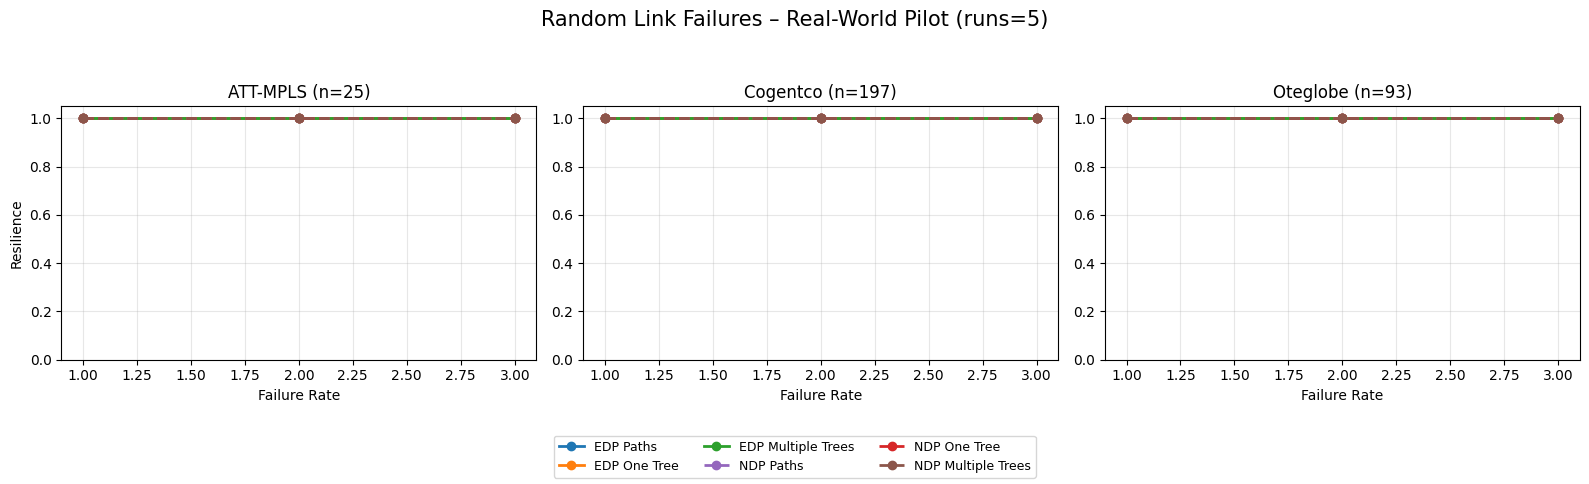

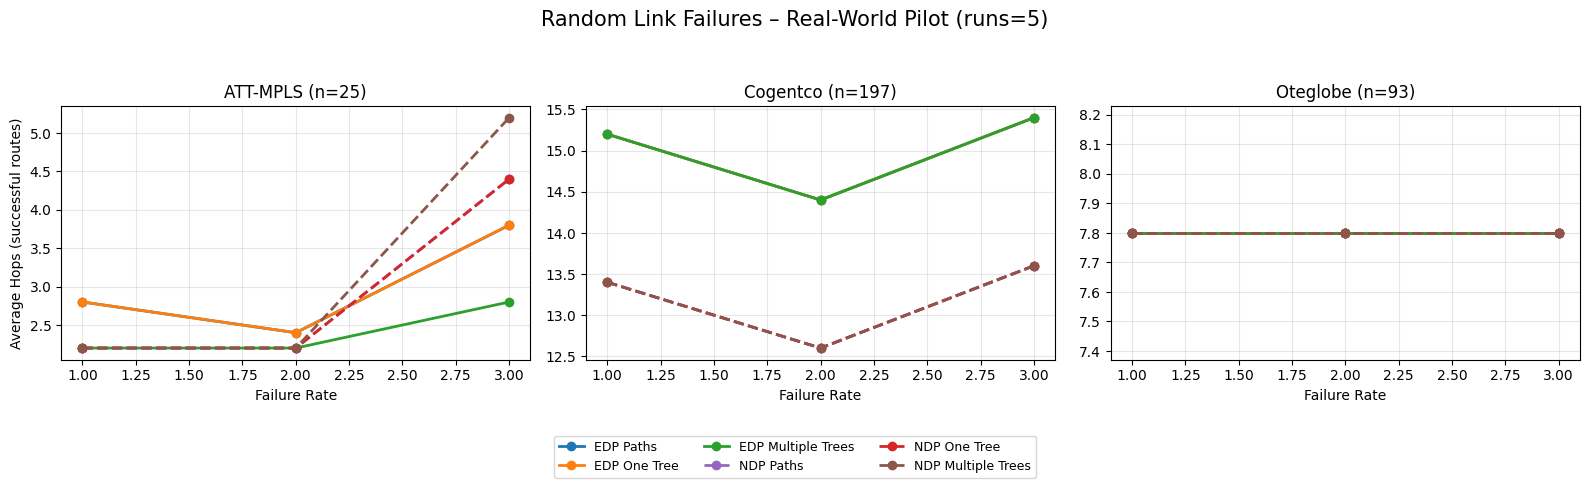

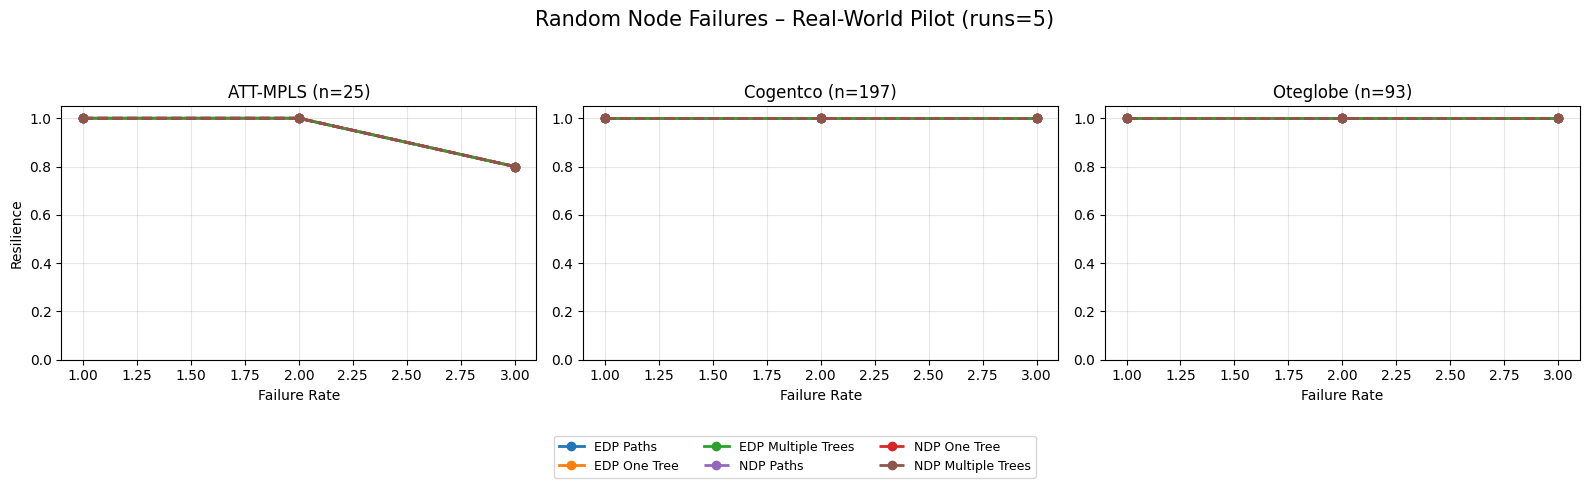

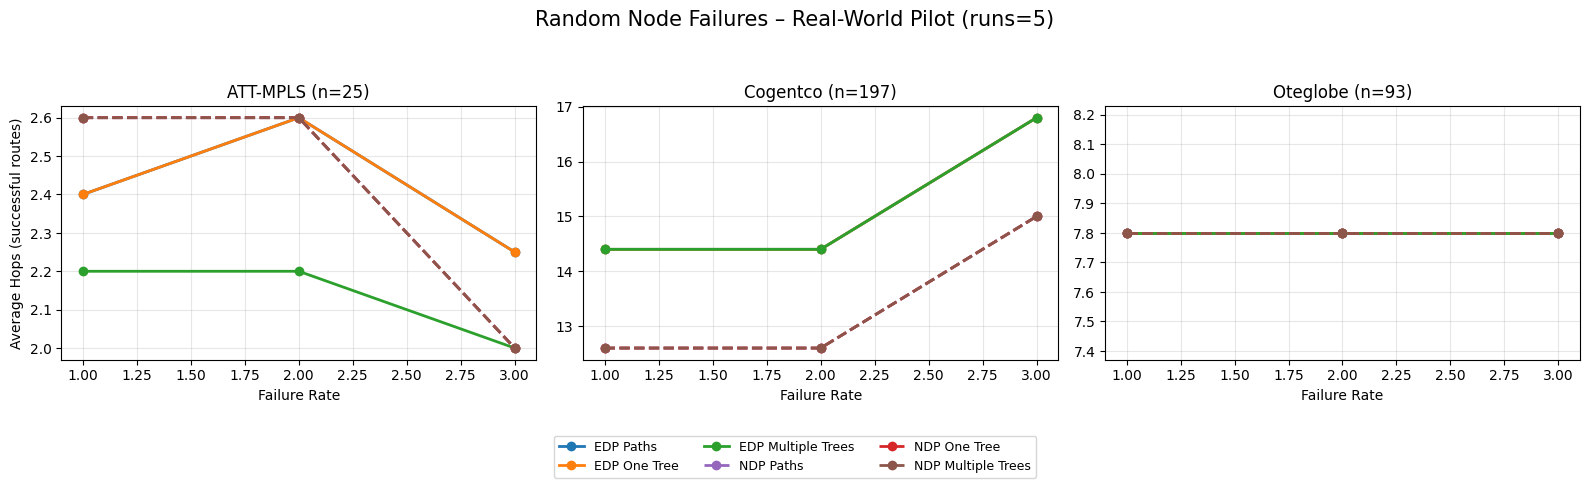

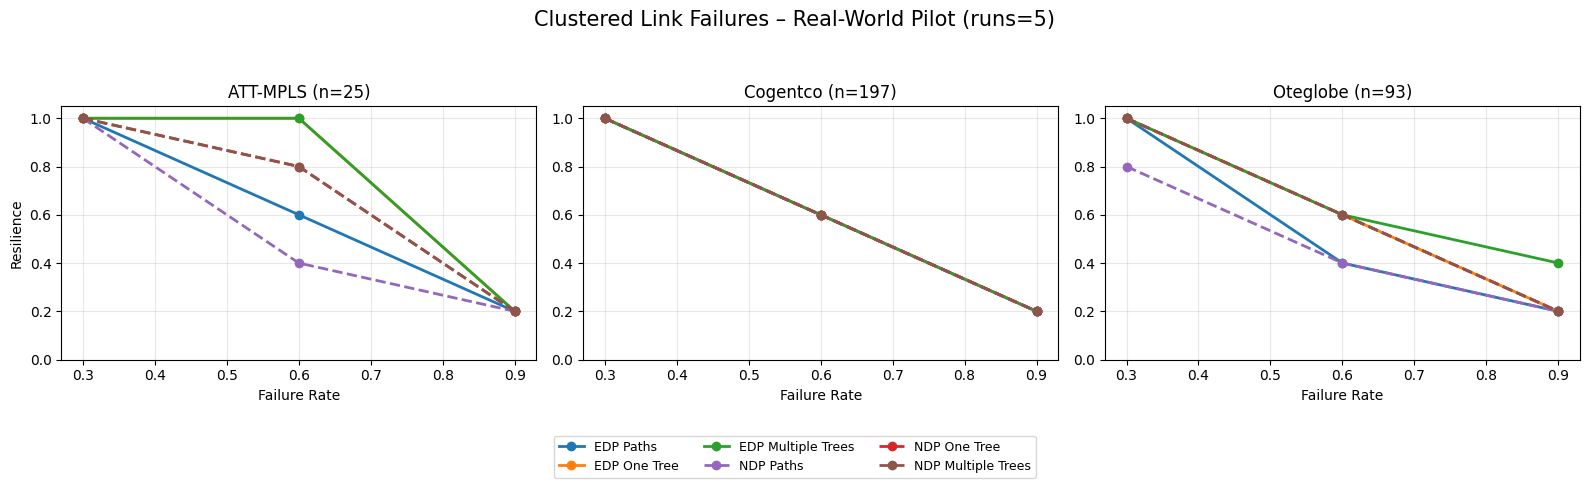

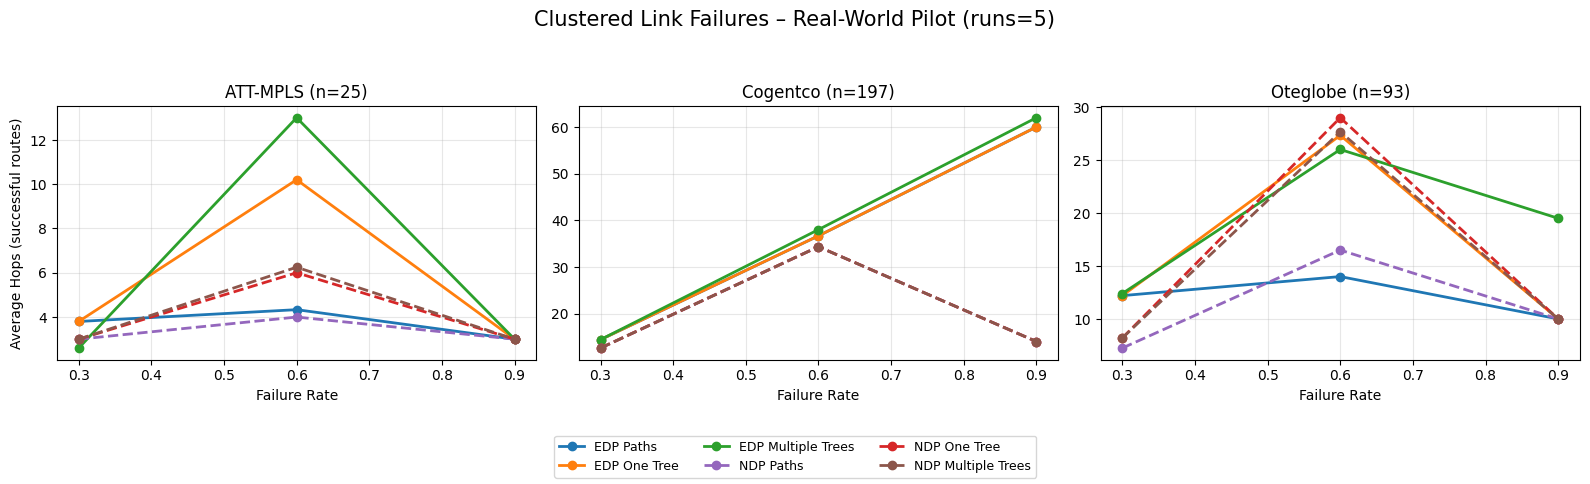

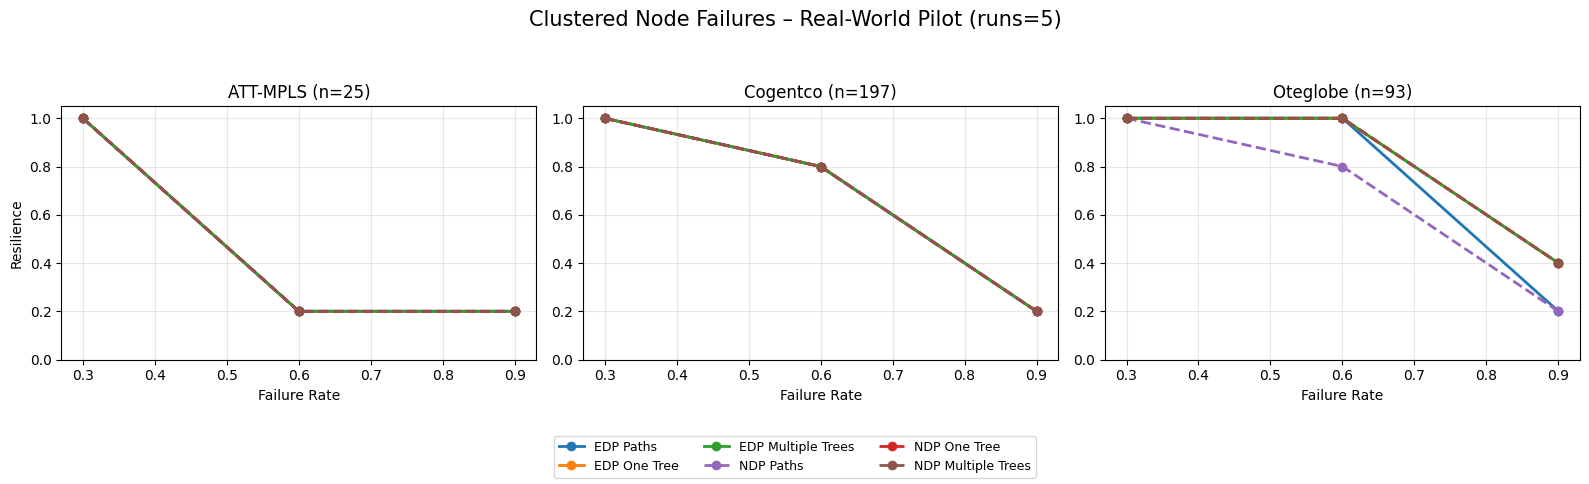

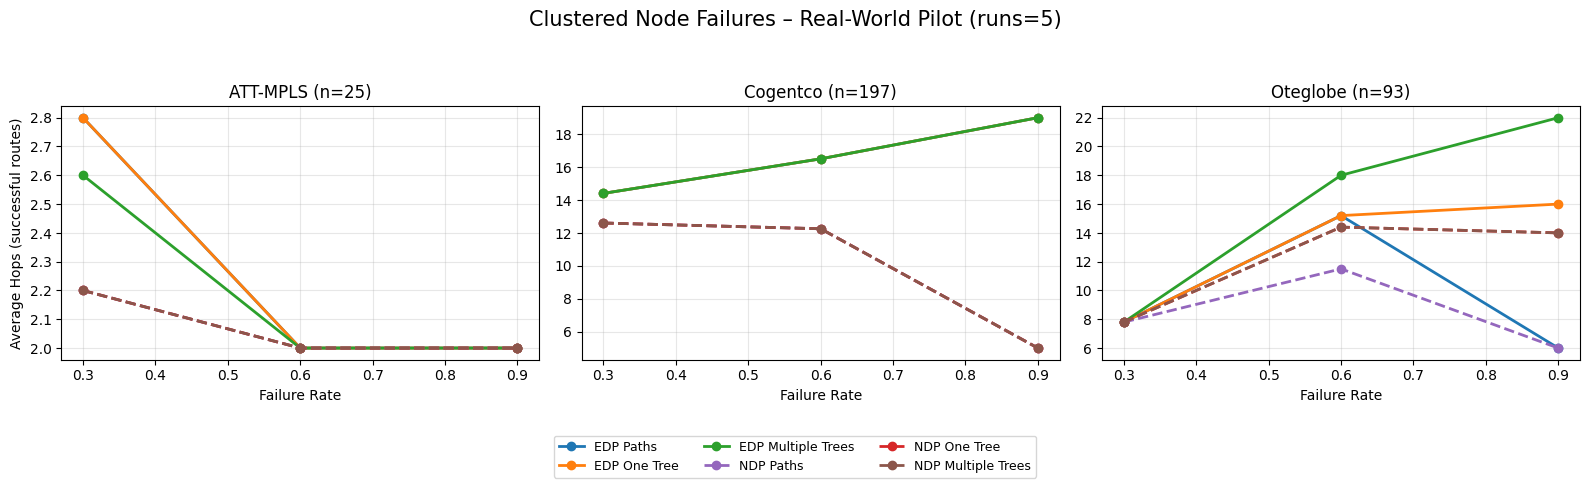

8 Hauptplots erzeugt.


In [5]:
labels = {
    'edp_paths': 'EDP Paths',
    'edp_one_tree': 'EDP One Tree',
    'edp_multiple_trees': 'EDP Multiple Trees',
    'ndp_paths': 'NDP Paths',
    'ndp_one_tree': 'NDP One Tree',
    'ndp_multiple_trees': 'NDP Multiple Trees',
}
colors = {
    'edp_paths': '#1f77b4', 'edp_one_tree': '#ff7f0e',
    'edp_multiple_trees': '#2ca02c', 'ndp_paths': '#9467bd',
    'ndp_one_tree': '#d62728', 'ndp_multiple_trees': '#8c564b',
}

def plot_metric(failure_model, failure_type, metric, ylabel, ylim=None):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=False)
    for ax, graph_name in zip(axes, TOPOLOGIES):
        subset = summary[
            (summary['graphName'] == graph_name)
            & (summary['failureModel'] == failure_model)
            & (summary['failureType'] == failure_type)
        ]
        for algorithm in routing.ALGORITHMS:
            values = subset[subset['algorithm'] == algorithm].sort_values('failureParameter')
            ax.plot(
                values['failureParameter'], values[metric], marker='o', linewidth=2,
                color=colors[algorithm], label=labels[algorithm],
                linestyle='--' if algorithm.startswith('ndp_') else '-',
            )
        ax.set_title(DISPLAY_NAMES[graph_name])
        ax.set_xlabel('Failure Rate')
        ax.grid(True, alpha=0.3)
        if ylim is not None:
            ax.set_ylim(*ylim)
    axes[0].set_ylabel(ylabel)
    fig.suptitle(
        f'{failure_model.title()} {failure_type.title()} Failures – Real-World Pilot (runs={RUNS})',
        fontsize=15,
    )
    handles, legend_labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, legend_labels, loc='lower center', ncol=3, fontsize=9)
    fig.tight_layout(rect=(0, 0.13, 1, 0.93))
    output = plot_dir / f'{failure_model}_{failure_type}_{metric}.png'
    fig.savefig(output, dpi=180, bbox_inches='tight')
    plt.show()
    return output

plot_paths = []
for failure_model in ['random', 'clustered']:
    for failure_type in ['link', 'node']:
        plot_paths.append(plot_metric(failure_model, failure_type, 'resilience', 'Resilience', (0, 1.05)))
        plot_paths.append(plot_metric(failure_model, failure_type, 'avgHops', 'Average Hops (successful routes)'))

print(f'{len(plot_paths)} Hauptplots erzeugt.')

## Stretch-Plots

Diese Zelle erzeugt den durchschnittlichen Stretch separat, damit die Hauptauswertung übersichtlicher bleibt.


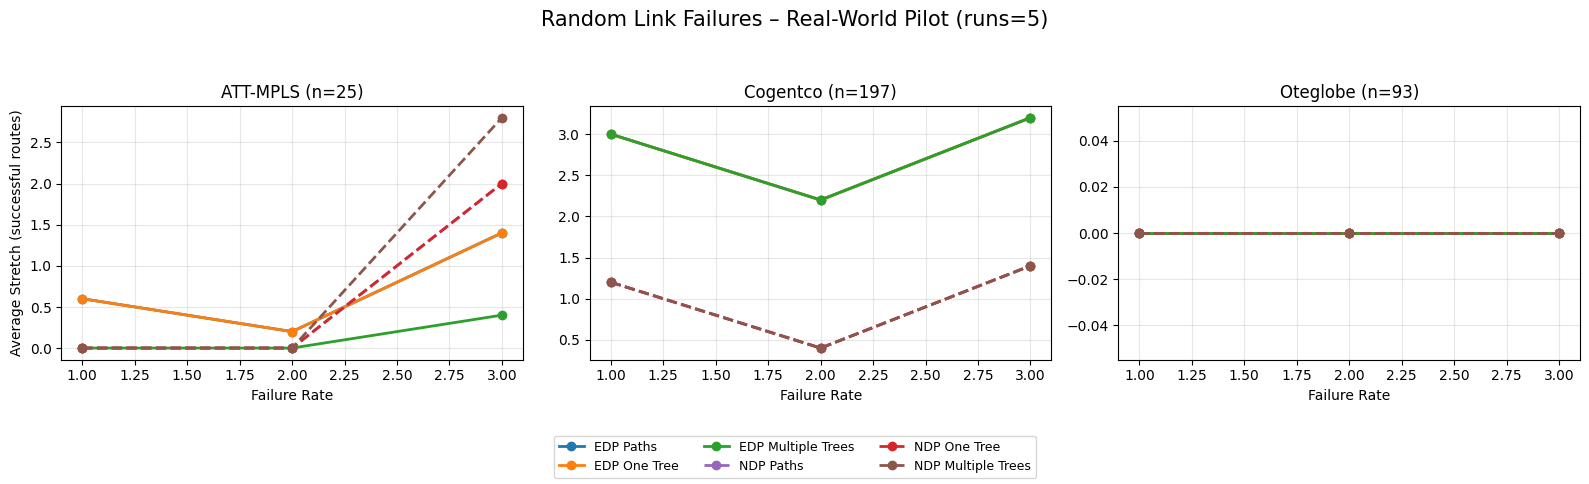

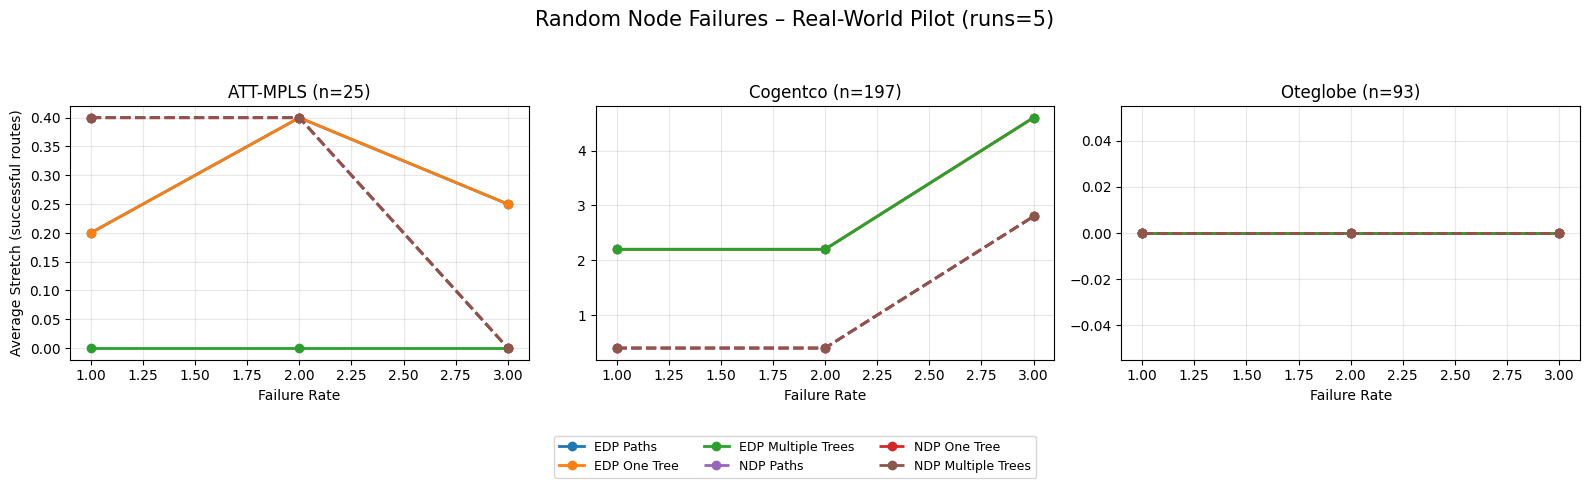

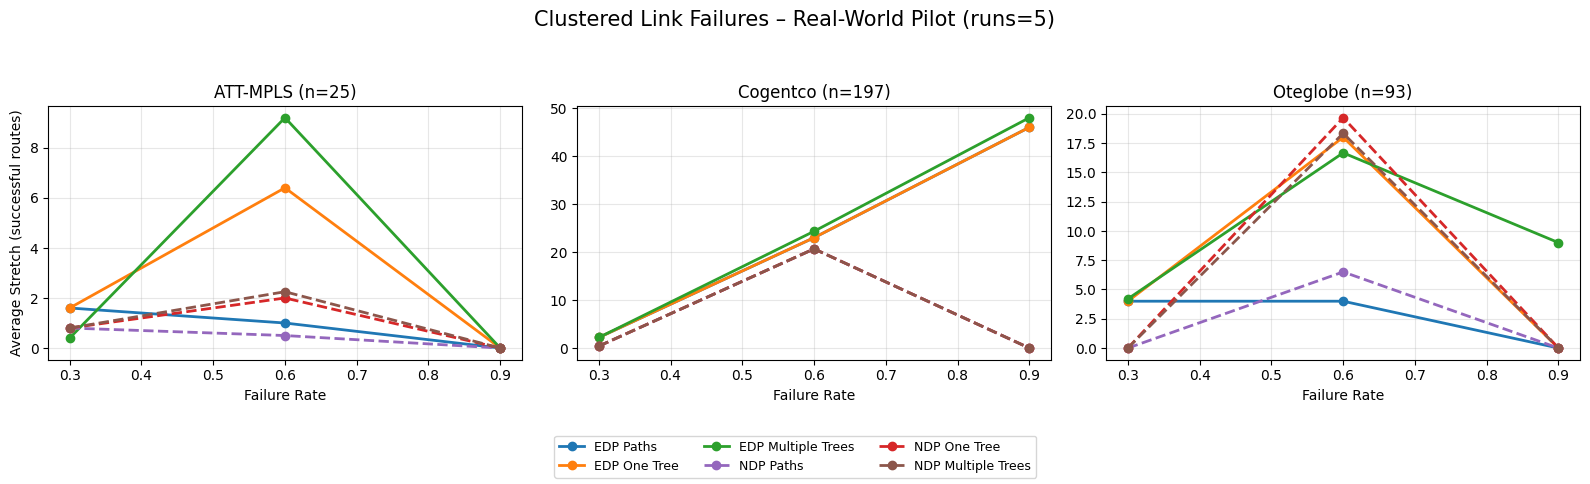

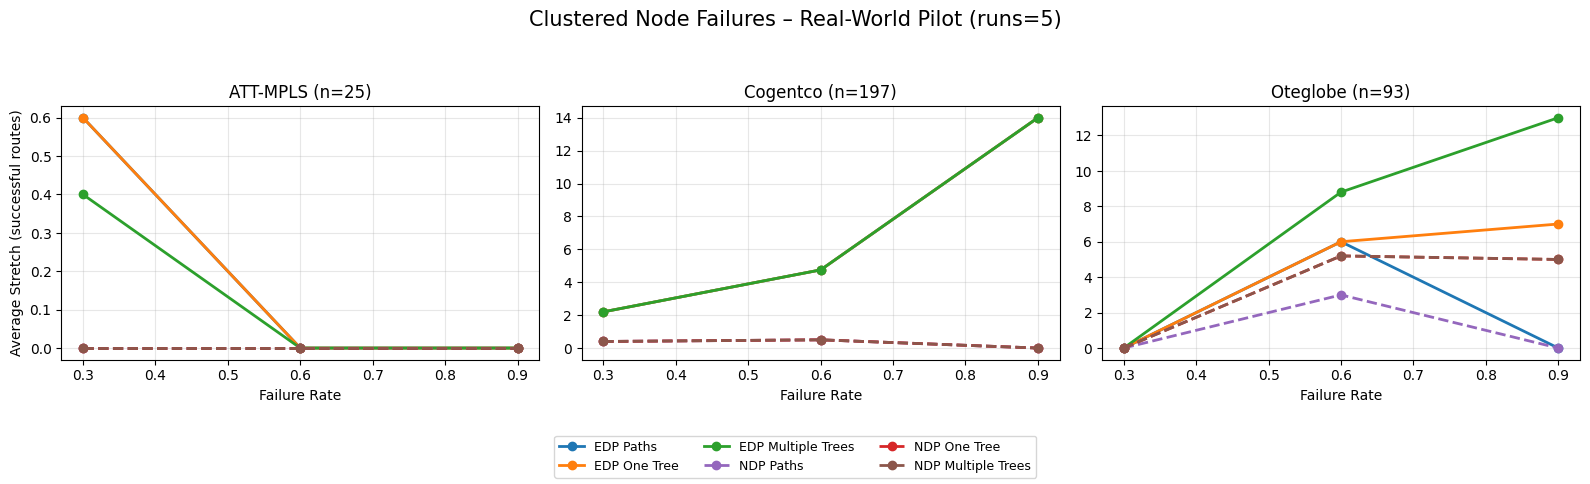

4 Stretch-Plots erzeugt.


In [6]:
stretch_plot_paths = []
for failure_model in ['random', 'clustered']:
    for failure_type in ['link', 'node']:
        stretch_plot_paths.append(plot_metric(failure_model, failure_type, 'avgStretch', 'Average Stretch (successful routes)'))

print(f'{len(stretch_plot_paths)} Stretch-Plots erzeugt.')

## Technische Plausibilitätsprüfung

Die folgenden Assertions prüfen Vollständigkeit und Wertebereiche, nicht die statistische Aussagekraft des Piloten.

In [7]:
expected_rows = len(TOPOLOGIES) * expected_files_per_topology * expected_rows_per_file
assert len(raw) == expected_rows
assert set(raw['graphName']) == set(TOPOLOGIES)
assert set(raw['algorithm']) == set(routing.ALGORITHMS)
assert set(zip(raw['failureType'], raw['failureModel'])) == {
    ('link', 'random'), ('node', 'random'),
    ('link', 'clustered'), ('node', 'clustered'),
}
assert raw.groupby(
    ['graphName', 'failureType', 'failureModel', 'failureParameter', 'algorithm']
).size().eq(RUNS).all()
assert summary['resilience'].between(0, 1).all()
assert len(plot_paths) == 8
assert len(stretch_plot_paths) == 4
assert all(path.exists() and path.stat().st_size > 0 for path in plot_paths + stretch_plot_paths)
assert summary_path.exists() and summary_path.stat().st_size > 0
print('Real-World-Pilot vollständig und technisch plausibel.')

Real-World-Pilot vollständig und technisch plausibel.


## Finale 1000-Run-Auswertung

Ab hier werden die vollstaendigen Serverdaten geladen, geprueft und zu den finalen Abbildungen aggregiert.


## Serverdaten laden und vollständig prüfen

In [8]:
raw_input, files_by_dataset = load_result_directories(DATASETS)
raw, summary = aggregate_results(raw_input)
validate_summary(summary, EXPECTED_RUNS, routing.ALGORITHMS)

print('CSV-Dateien:', sum(len(files) for files in files_by_dataset.values()))
print('Rohdatenzeilen:', len(raw))
print('Aggregierte Zeilen:', len(summary))
completeness_table(summary)

CSV-Dateien: 102
Rohdatenzeilen: 612000
Aggregierte Zeilen: 612


algorithms  \
dataset  failureType failureModel failureParameter               
attmpls  link        clustered    0.3                        6   
                                  0.4                        6   
                                  0.5                        6   
                                  0.6                        6   
                                  0.7                        6   
...                                                        ...   
oteglobe node        random       6.0                        6   
                                  7.0                        6   
                                  8.0                        6   
                                  9.0                        6   
                                  10.0                       6   

                                                    samplesPerAlgorithm  
dataset  failureType failureModel failureParameter                       
attmpls  link        clustered    0.3                              1000  
                                  0.4                              1000  
                                  0.5                              1000  
                                  0.6                              1000  
                                  0.7                              1000  
...                                                                 ...  
oteglobe node        random       6.0                              1000  
                                  7.0                              1000  
                                  8.0                              1000  
                                  9.0                              1000  
                                  10.0                             1000  

[102 rows x 2 columns]

## Finale PNG- und SVG-Plots erzeugen

Die X-Achse wird paper-nah einheitlich als **Failure Rate** beschriftet. Technisch entspricht sie bei Random Failures dem `failFactor` und bei Clustered Failures dem `failureStart`.

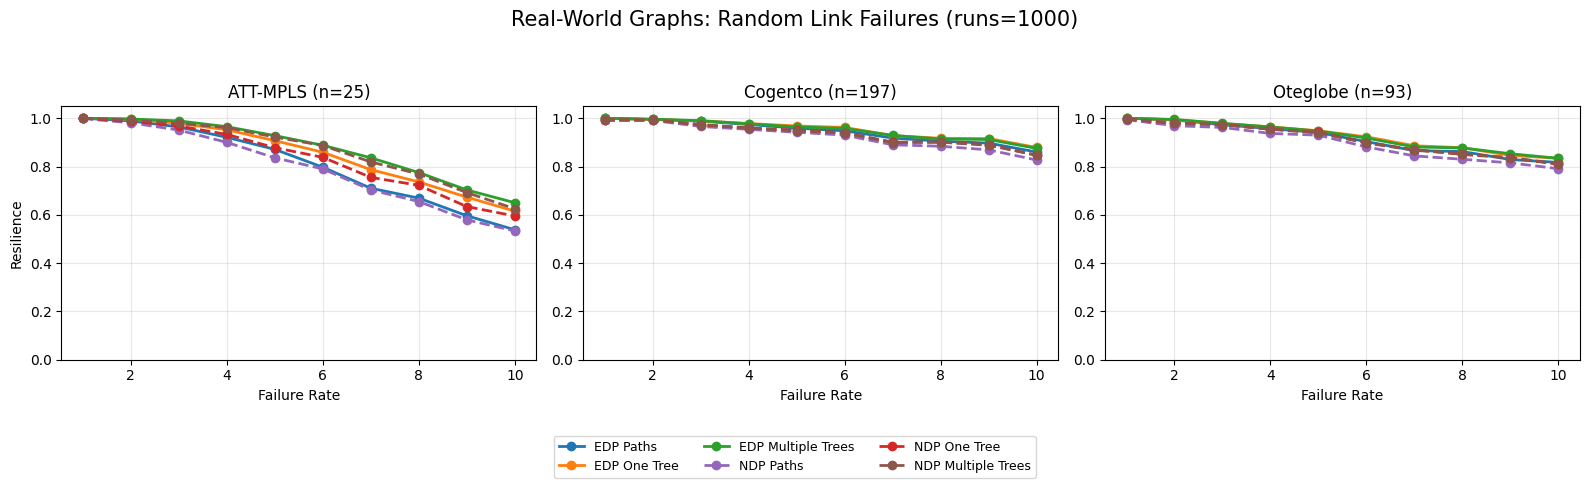

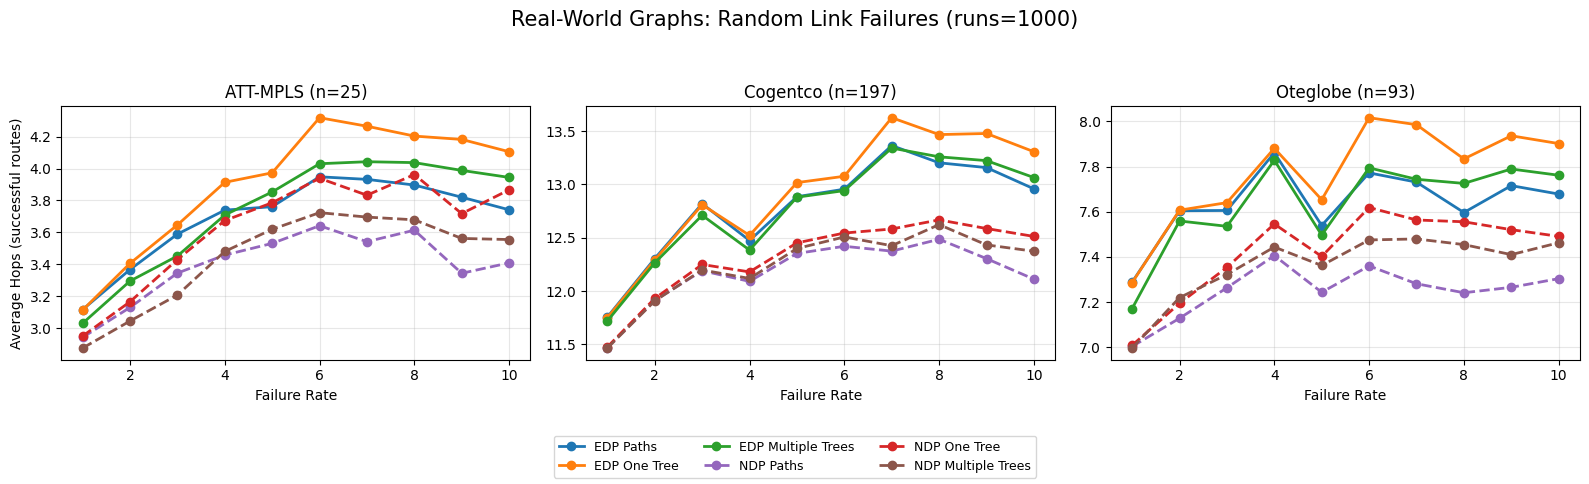

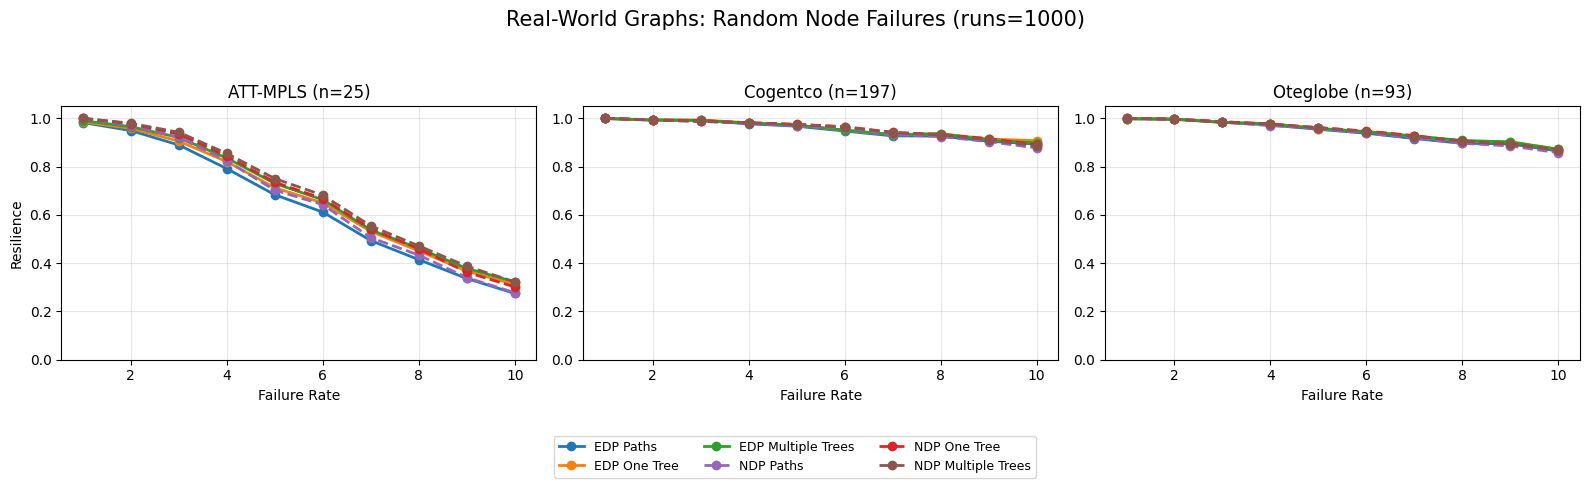

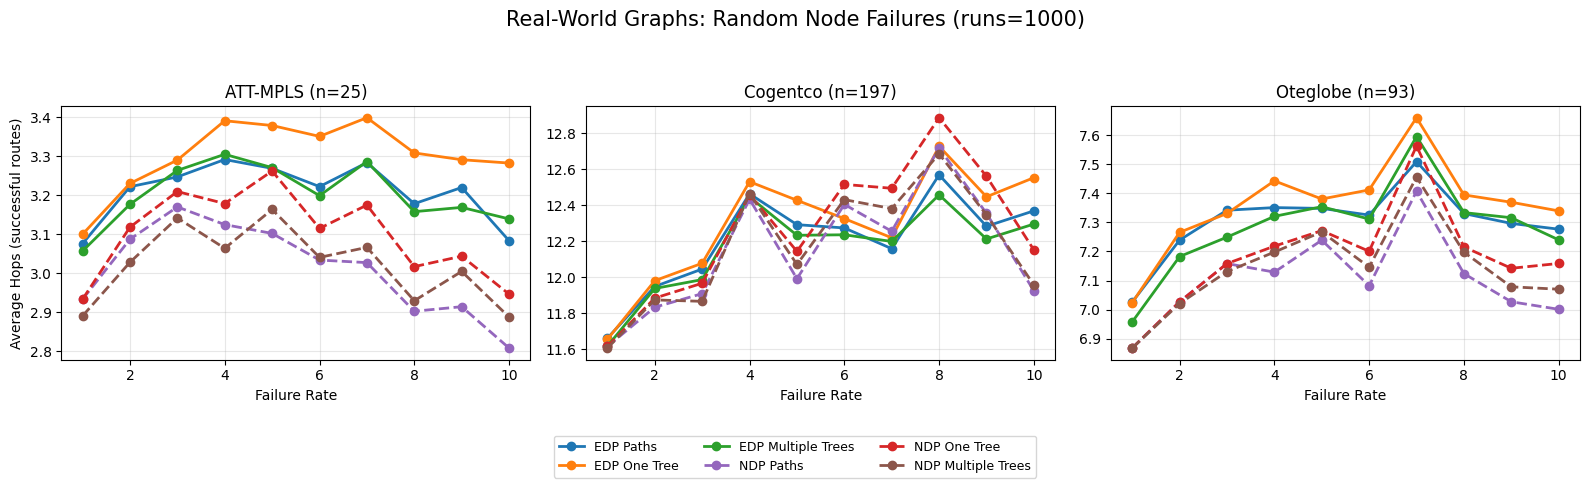

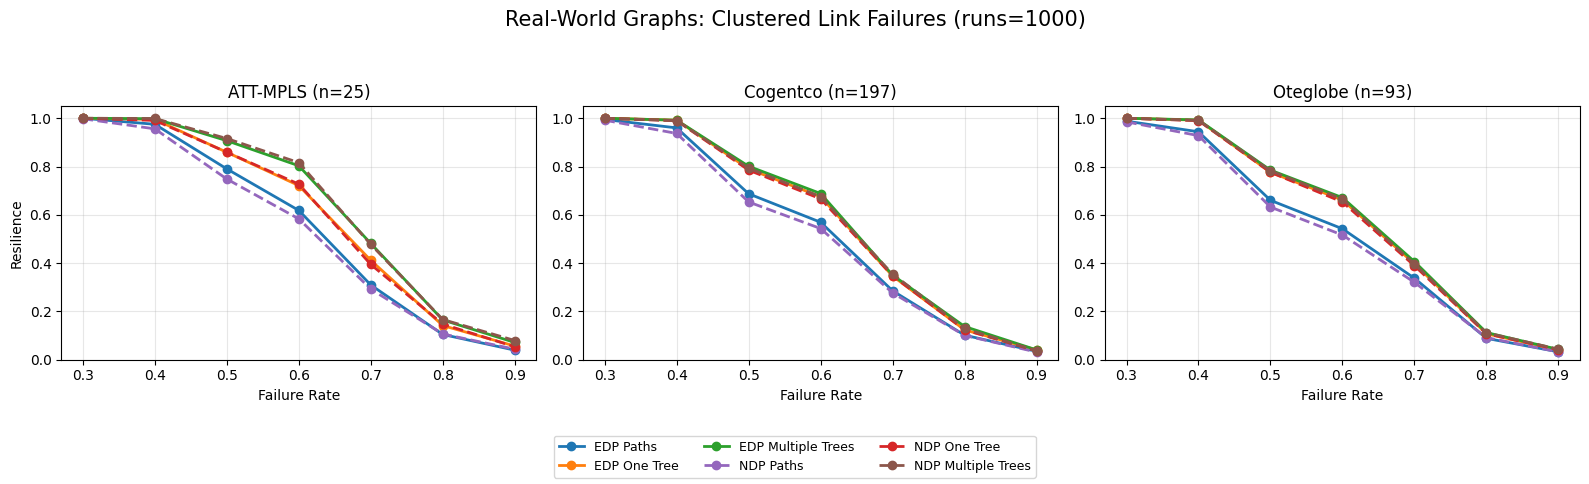

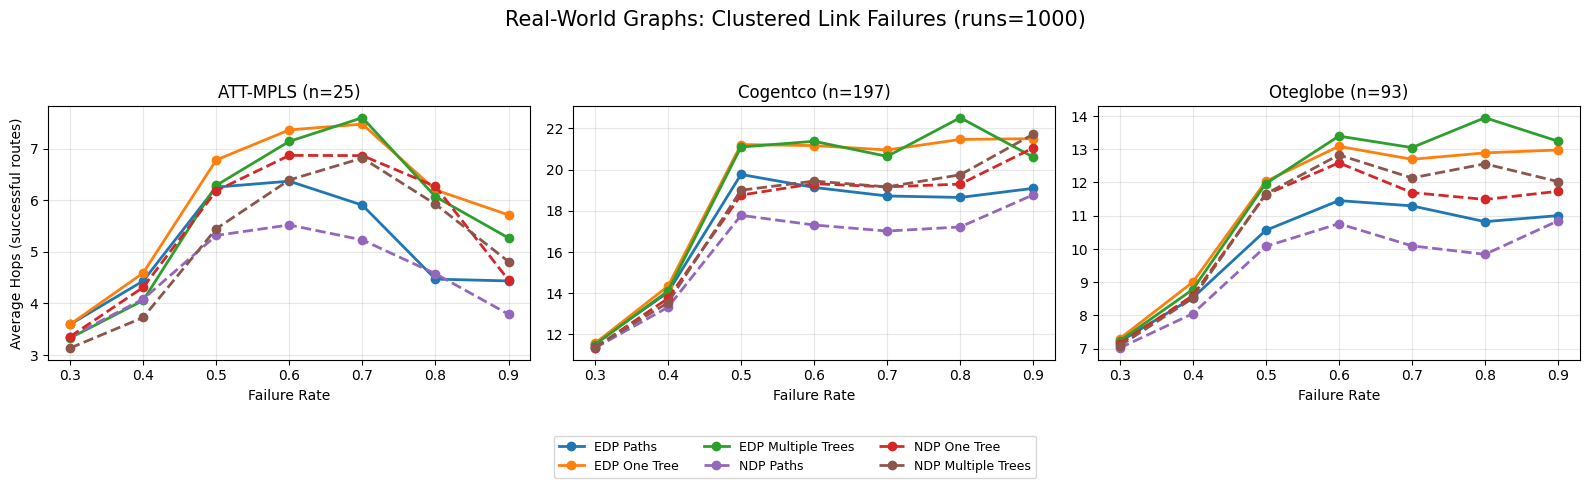

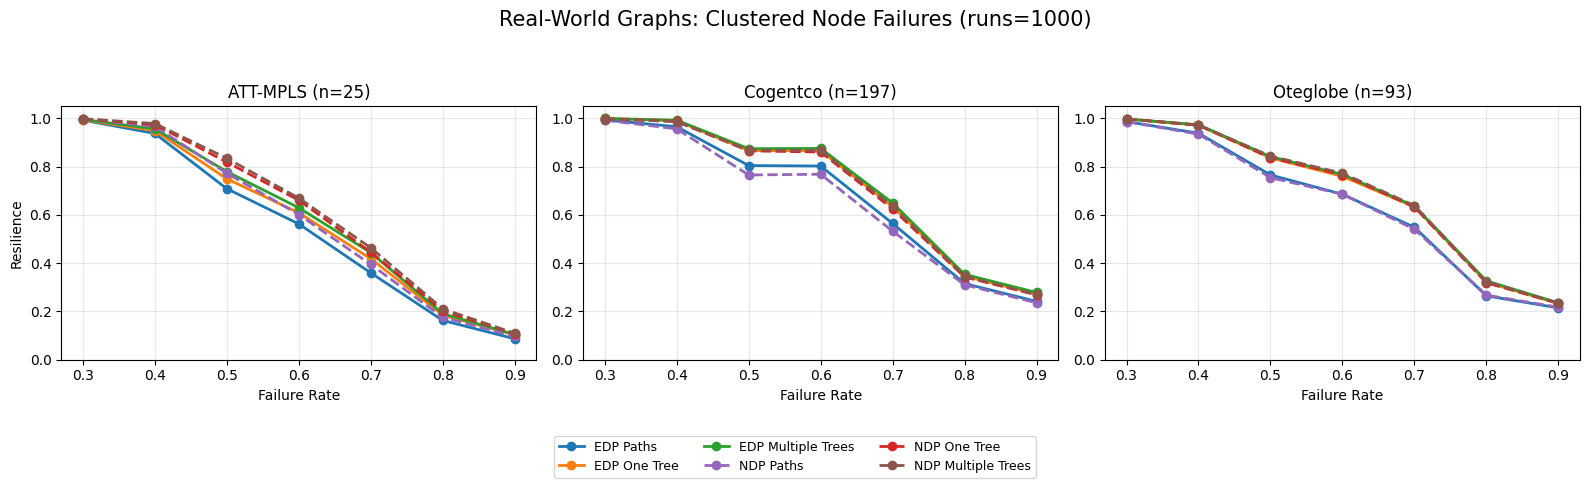

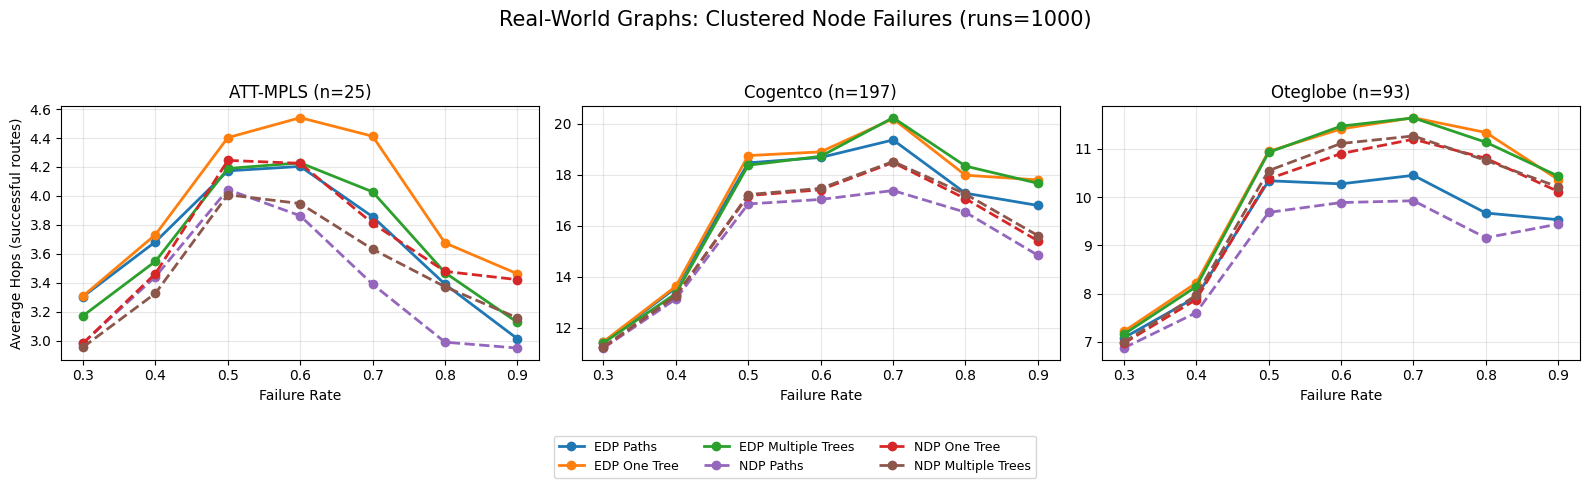

Summary: C:\Users\test\ba-gamous-disjoint\schritt4_algorithmen_vergleich\evaluation\output\real_world_graphs_runs1000\real_world_graphs_runs1000_summary.csv
Hauptplotdateien: 16


In [9]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
summary_path = OUTPUT_DIR / 'real_world_graphs_runs1000_summary.csv'
summary.to_csv(summary_path, index=False)
main_plot_paths = plot_all_comparisons(
    summary=summary, datasets=list(DATASETS), display_names=DISPLAY_NAMES,
    algorithms=routing.ALGORITHMS, output_dir=OUTPUT_DIR,
    title_prefix='Real-World Graphs', runs=EXPECTED_RUNS,
    metrics=[
        ('resilience', 'Resilience', (0, 1.05)),
        ('avgHops', 'Average Hops (successful routes)', None),
    ],
)
assert len(main_plot_paths) == 16
assert all(path.exists() and path.stat().st_size > 0 for path in main_plot_paths)
print('Summary:', summary_path)
print('Hauptplotdateien:', len(main_plot_paths))

## Summary-CSV anzeigen

Diese Zelle liest die gespeicherte Summary-CSV erneut ein und zeigt sie als Tabelle im Notebook an.


In [10]:
import pandas as pd

summary_csv = OUTPUT_DIR / "real_world_graphs_runs1000_summary.csv"
summary_df = pd.read_csv(summary_csv)

print("Summary-Datei:", summary_csv)
print("Zeilen:", len(summary_df))
display(summary_df)

Summary-Datei: C:\Users\test\ba-gamous-disjoint\schritt4_algorithmen_vergleich\evaluation\output\real_world_graphs_runs1000\real_world_graphs_runs1000_summary.csv
Zeilen: 612


,dataset,failureType,failureModel,failureParameter,algorithm,resilience,avgHops,avgStretch,samples,successes
0,attmpls,link,clustered,0.3,edp_multiple_trees,1.000,3.330000,0.557000,1000,1000
1,attmpls,link,clustered,0.3,edp_one_tree,1.000,3.594000,0.821000,1000,1000
2,attmpls,link,clustered,0.3,edp_paths,1.000,3.594000,0.821000,1000,1000
3,attmpls,link,clustered,0.3,ndp_multiple_trees,1.000,3.136000,0.363000,1000,1000
4,attmpls,link,clustered,0.3,ndp_one_tree,1.000,3.357000,0.584000,1000,1000
...,...,...,...,...,...,...,...,...,...,...
607,oteglobe,node,random,10.0,edp_one_tree,0.872,7.339450,0.613532,1000,872
608,oteglobe,node,random,10.0,edp_paths,0.864,7.276620,0.572917,1000,864
609,oteglobe,node,random,10.0,ndp_multiple_trees,0.868,7.070276,0.346774,1000,868
610,oteglobe,node,random,10.0,ndp_one_tree,0.869,7.158803,0.420023,1000,869


## Stretch-Plots

Diese Zelle erzeugt den durchschnittlichen Stretch separat, damit Resilience und Hops als Hauptplots übersichtlich bleiben.


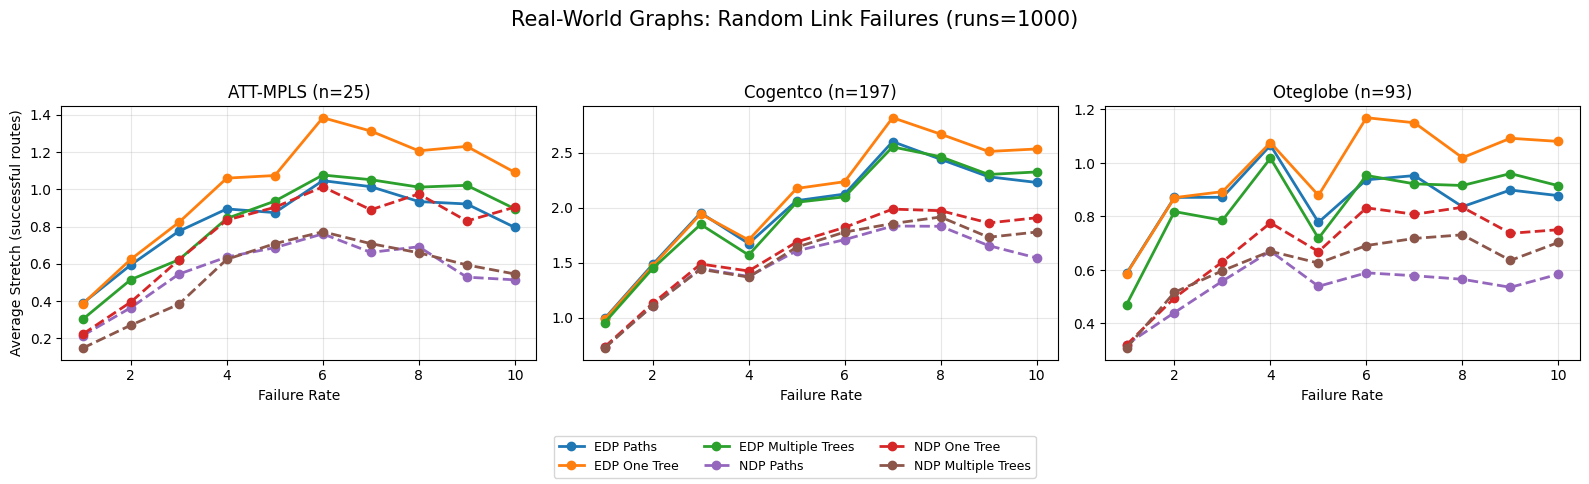

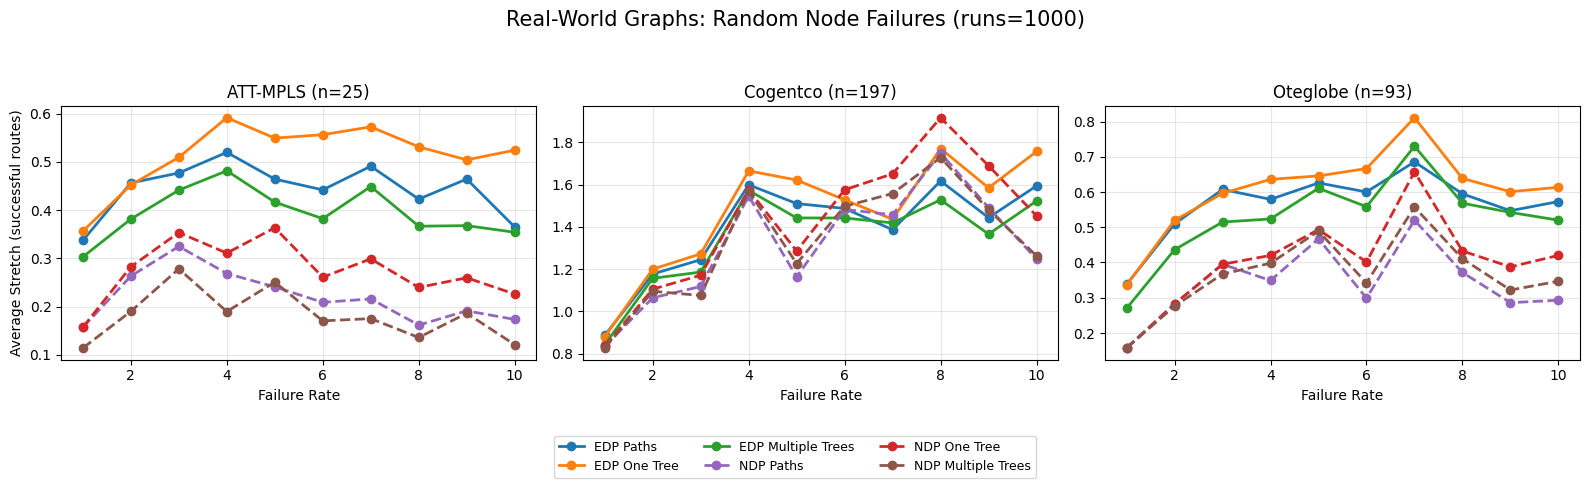

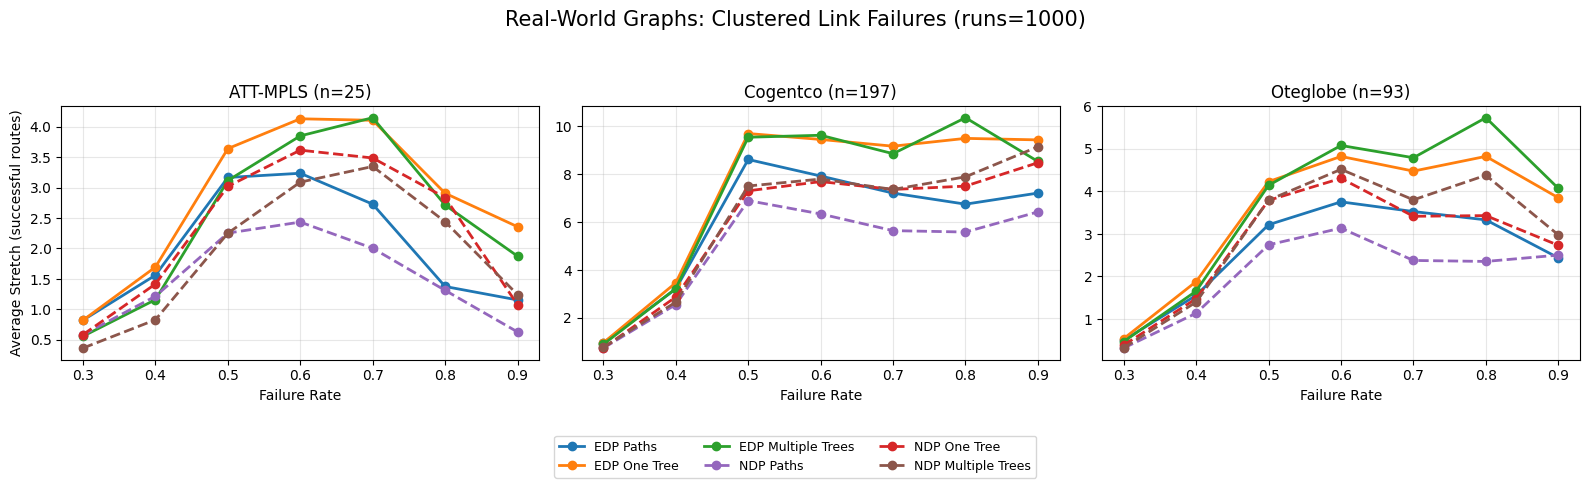

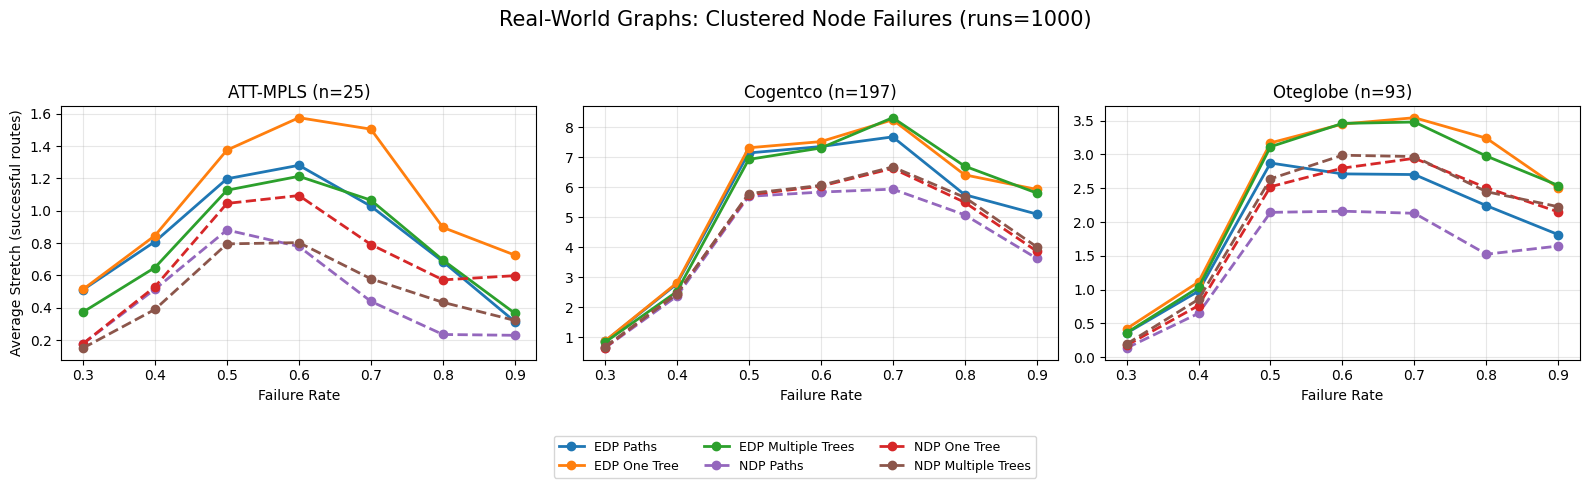

Stretch-Plotdateien: 8


In [11]:
stretch_plot_paths = plot_all_comparisons(
    summary=summary, datasets=list(DATASETS), display_names=DISPLAY_NAMES,
    algorithms=routing.ALGORITHMS, output_dir=OUTPUT_DIR,
    title_prefix='Real-World Graphs', runs=EXPECTED_RUNS,
    metrics=[('avgStretch', 'Average Stretch (successful routes)', None)],
)
assert len(stretch_plot_paths) == 8
assert all(path.exists() and path.stat().st_size > 0 for path in stretch_plot_paths)
print('Stretch-Plotdateien:', len(stretch_plot_paths))